# Image Captioning - Base model + Evaluation.
## Authors: Erfan Ahmadi, Mohammad Ali Olama

# Part 1: Preparing Dataset

In [1]:
import os
import json
import re
from collections import Counter
import numpy as np
from PIL import Image

import torch
from torch.utils.data import Dataset
import torchvision.transforms as transforms
from datasets import load_dataset  # <-- ADD THIS IMPORT
from huggingface_hub import login
from datasets import load_from_disk

import matplotlib.pyplot as plt

print("All libraries imported successfully.")

All libraries imported successfully.


## Download Data and Display Samples

For the loading dataset part, I got strange errors at loading from Hugging face in this notebook. Hence, I had to download the dataset from somewhere else, upload it to my drive, and again download from drive to the local server. The commented code bellow is for downloading the dataset from Hugging face : 

In [80]:
# ds = load_dataset("jxie/flickr8k")  # -> dict with 'train', 'validation', 'test'
# # print(ds)

In [81]:
# ds.save_to_disk("./flickr8k_dataset")

Load  the data from the Disk

In [3]:
ds = load_from_disk("./flickr8k_dataset")
print("Dataset loaded successfully.")

Dataset loaded successfully.



Dataset Structure:
DatasetDict({
    train: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
})

Exploring the 'train' split:
Displaying the 1th image from the training set with its 5 captions:


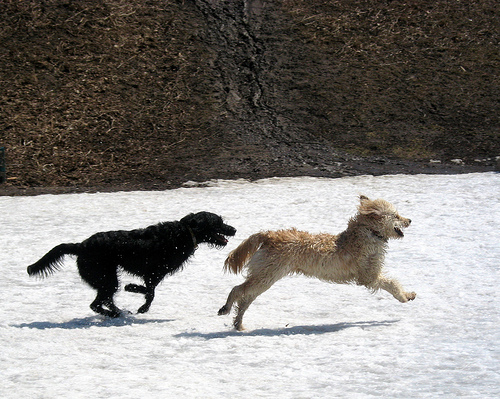

  - Caption 0: A black dog is running after a white dog in the snow .
  - Caption 1: Black dog chasing brown dog through snow
  - Caption 2: Two dogs chase each other across the snowy ground .
  - Caption 3: Two dogs play together in the snow .
  - Caption 4: Two dogs running through a low lying body of water .
Displaying the 2th image from the training set with its 5 captions:


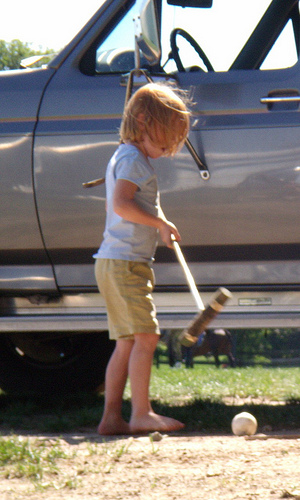

  - Caption 0: A little baby plays croquet .
  - Caption 1: A little girl plays croquet next to a truck .
  - Caption 2: The child is playing croquette by the truck .
  - Caption 3: The kid is in front of a car with a put and a ball .
  - Caption 4: The little boy is playing with a croquet hammer and ball beside the car .
Displaying the 3th image from the training set with its 5 captions:


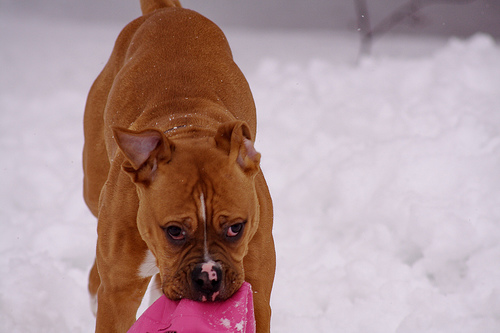

  - Caption 0: A brown dog in the snow has something hot pink in its mouth .
  - Caption 1: A brown dog in the snow holding a pink hat .
  - Caption 2: A brown dog is holding a pink shirt in the snow .
  - Caption 3: A dog is carrying something pink in its mouth while walking through the snow .
  - Caption 4: A dog with something pink in its mouth is looking forward .


In [5]:
print("\nDataset Structure:")
print(ds)

# --- Display a few Samples ---
print("\nExploring the 'train' split:")
train_data = ds['train']

for i in range (3):
    sample = train_data[i]
    print(f"Displaying the {i+1}th image from the training set with its 5 captions:")
    display(sample['image']) # In a Jupyter environment, this displays the image.

    for j in range(5):
        print(f"  - Caption {j}: {sample[f'caption_{j}']}")

* **DatasetDict**: The loaded object `ds` is a `DatasetDict`. This is a dictionary-like object where keys are the names of the data splits (`train`, `validation`, `test`) and values are the `Dataset` objects themselves.
* **Data Structure**: We explore a single sample to confirm the structure. Each row contains:
    - An `'image'` key holding a PIL `Image` object.
    - Five distinct keys, `'caption_0'` through `'caption_4'`, each holding one of the five caption strings for that image.

## Create and Build the Vocabulary

**Here, we define a Vocabulary class to handle all text preprocessing tasks. This includes cleaning, tokenizing, and converting text to numbers**

In [6]:
class Vocabulary:
    def __init__(self, freq_threshold):
        self.freq_threshold = freq_threshold
        self.itos = {0: "<pad>", 1: "<sos>", 2: "<eos>", 3: "<unk>"}
        self.stoi = {"<pad>": 0, "<sos>": 1, "<eos>": 2, "<unk>": 3}
    
    def __len__(self):
        return len(self.itos)

    @staticmethod
    def preprocess_text(text):
        text = text.lower()
        text = re.sub(r'[^\w\s]', '', text)
        return text.split()

    def build_vocabulary(self, sentence_list):
        frequencies = Counter()
        idx = 4
        for sentence in sentence_list:
            for word in self.preprocess_text(sentence):
                frequencies[word] += 1
                if frequencies[word] == self.freq_threshold:
                    self.stoi[word] = idx
                    self.itos[idx] = word
                    idx += 1
    
    def numericalize(self, text):
        """Converts a text sentence to a sequence of numerical IDs."""
        tokenized_text = self.preprocess_text(text)
        return [self.stoi.get(token, self.stoi["<unk>"]) for token in tokenized_text]
        
    def save_vocabulary(self, file_path):
        with open(file_path, 'w') as f:
            json.dump(self.stoi, f, indent=4)
            
    @staticmethod
    def load_vocabulary(file_path):
        """Creates a Vocabulary instance from a saved JSON file."""
        vocab = Vocabulary(freq_threshold=0)
        with open(file_path, 'r') as f:
            vocab.stoi = json.load(f)
        vocab.itos = {idx: word for word, idx in vocab.stoi.items()}
        return vocab

Now we can build the vocabs 

In [23]:

# If the file doesn't exist, build it from the dataset.
print(f"Vocabulary file not found. Building a new one...")

# 1. Gather all captions from all splits.
all_captions = []
for split in ds:
    for example in ds[split]:
        for i in range(5):
            all_captions.append(example[f'caption_{i}'])

# 2. Instantiate and build the vocabulary.
vocab = Vocabulary(freq_threshold=4)
vocab.build_vocabulary(all_captions)

# 3. Save the newly built vocabulary for next time.
# vocab.save_vocabulary(vocab_file)
# print(f"Vocabulary built and saved to '{vocab_file}'.")

print(f"Final vocabulary size: {len(vocab)} words.")

Vocabulary file not found. Building a new one...
Final vocabulary size: 3381 words.


* **Vocabulary Class**: This class centralizes text processing logic.
    - `preprocess_text`: This static method handles caption cleaning. It **converts text to lowercase**, **removes punctuation and numbers**, and **tokenizes** the string into a list of words.
    - `build_vocabulary`: This method creates the word-to-ID mapping. It only includes words that appear at least `freq_threshold` times to filter out rare words and noise.
* **Special Tokens**: The `__init__` method pre-defines four essential tokens:
    - **`<pad>`**: (Padding) A token used to fill shorter sequences to a fixed length.
    - **`<sos>`**: (Start of Sequence) A token that signals the beginning of a caption.
    - **`<eos>`**: (End of Sequence) A token that signals the end of a caption.
    - **`<unk>`**: (Unknown) A token that represents any word not present in our vocabulary.
* **Saving**: The `save_vocabulary` method **saves the `stoi` (string-to-index) dictionary to a JSON file**. This is critical for ensuring the same vocabulary is used when you later test or deploy the model.

## Create the Custom PyTorch Dataset

This cell defines a custom Dataset class that prepares one image-caption pair for the model. It integrates image transformations and caption padding.

Tasks covered : 

* Resize the images to appropriate dimensions for CNN model input.

* Normalize pixel values using the mean and standard deviation.

* Set a fixed length for sequences and use \<pad> to fill them.

In [24]:
class FlickrDataset(Dataset):
    def __init__(self, hf_split, vocab, transform=None, seq_length=25):
        self.hf_split = hf_split
        self.vocab = vocab
        self.transform = transform
        self.seq_length = seq_length

    def __len__(self):
        return len(self.hf_split) * 5

    def __getitem__(self, index):
        image_idx = index // 5
        caption_idx = index % 5

        data_point = self.hf_split[image_idx]

        image = data_point['image'].convert("RGB")
        caption = data_point[f'caption_{caption_idx}']

        # Apply image transformations (resize, normalize, etc.)
        if self.transform:
            image = self.transform(image)

        # Numericalize and add special tokens
        numericalized_caption = self.vocab.numericalize(caption)
        caption_vec = [self.vocab.stoi["<sos>"]]
        caption_vec.extend(numericalized_caption)
        caption_vec.append(self.vocab.stoi["<eos>"])

        # Pad or truncate to the fixed sequence length
        if len(caption_vec) < self.seq_length:
            caption_vec += [self.vocab.stoi["<pad>"]] * (self.seq_length - len(caption_vec))
        else:
            caption_vec = caption_vec[:self.seq_length]
            caption_vec[-1] = self.vocab.stoi["<eos>"]

        return image, torch.tensor(caption_vec)

* **Efficiency Check**: The core of this update is the `if os.path.exists(vocab_file):` block. This simple check from Python's `os` module determines whether to run the time-consuming build process or take the fast path of loading the file. 
* **Loading Logic**:
    - We've added a new `staticmethod` called **`load_vocabulary`** to the `Vocabulary` class. A static method belongs to the class itself rather than an instance of the class, making it a perfect factory for creating a `Vocabulary` object from a file.
    - Inside this method, it reads the saved JSON file to reconstruct the `stoi` (string-to-index) dictionary.
    - Crucially, it then rebuilds the `itos` (index-to-string) mapping from the loaded `stoi`. This inverse mapping is essential for converting the model's numerical output back into readable words.
* **Building Logic**: The `else` block contains the same logic as before: it gathers all captions, builds the vocabulary from scratch, and saves it. This part of the code will now only run the very first time you execute the script.

## Instantiate Datasets and Display a Processed Sample

In [25]:
# Define the pipeline of image transformations
image_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    ),
])

seq_length = 25

# Create dataset instances for each split
train_dataset = FlickrDataset(ds['train'], vocab, transform=image_transforms, seq_length=seq_length)
val_dataset = FlickrDataset(ds['validation'], vocab, transform=image_transforms, seq_length=seq_length)
test_dataset = FlickrDataset(ds['test'], vocab, transform=image_transforms, seq_length=seq_length)

print(f"Training set size: {len(train_dataset)} image-caption pairs")

# --- Display a Processed Sample ---
# Fetch a processed image and caption tensor
img_tensor, cap_tensor = train_dataset[12]

# Convert caption tensor back to words for display
caption_words = [vocab.itos[idx.item()] for idx in cap_tensor]
caption_text = " ".join(caption_words)

print("\n--- Processed Sample ---")
print(f"Image Tensor Shape: {img_tensor.shape}")
print(f"Caption Tensor: {cap_tensor}")
print(f"Processed Caption Text: {caption_text}")

Training set size: 30000 image-caption pairs

--- Processed Sample ---
Image Tensor Shape: torch.Size([3, 224, 224])
Caption Tensor: tensor([  1,   5,  10,   4,   7, 112,   5,  11,  23,   8,   6,   9,   2,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0])
Processed Caption Text: <sos> a brown dog is holding a pink shirt in the snow <eos> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>


* **`image_transforms`**: This `Compose` pipeline defines the steps for image processing that will be passed to our `FlickrDataset`.
    -   `Resize`: Sets all images to 224x224 pixels.
    -   `ToTensor`: Converts images to PyTorch tensors.
    -   `Normalize`: Normalizes tensors using ImageNet's mean and standard deviation.
* **Dataset Instantiation**: We create the `train_dataset`, `val_dataset`, and `test_dataset` that our model will use.
* **Display Processed Sample**: We fetch a single item (an image tensor and a caption tensor) from the dataset. To make the output human-readable, we convert the **processed caption** tensor back into words using the `vocab.itos` mapping and display the result. This confirms our entire pipeline is working correctly.

**The train and test split part is not needed because the hugging face data is already splited**

## Data Visualizations

Finally, we create plots to better understand our dataset's characteristics, such as the distribution of caption lengths and word frequencies.

Tasks Covered:

* Plot the distribution of sequence lengths.

* Draw a histogram of the top 20 most frequent words.

In [26]:
# Make all captions 
print("Gathering all captions for visualization...")
all_captions = []
for split in ds:
    for example in ds[split]:
        for i in range(5):
            all_captions.append(example[f'caption_{i}'])

Gathering all captions for visualization...


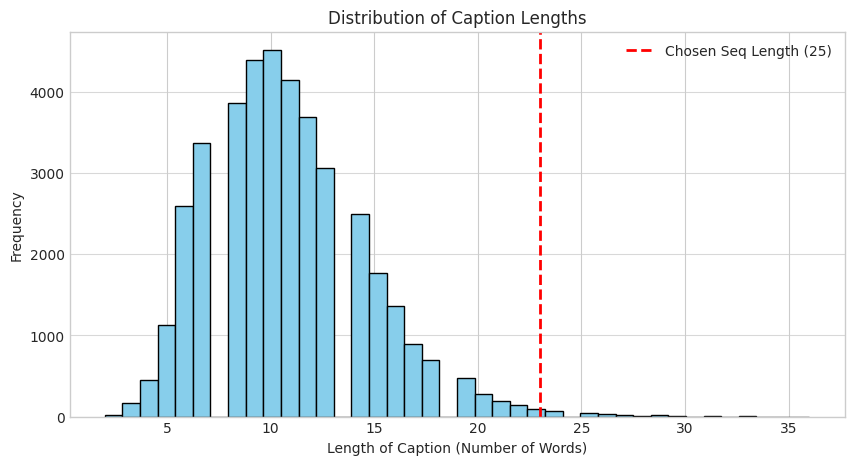

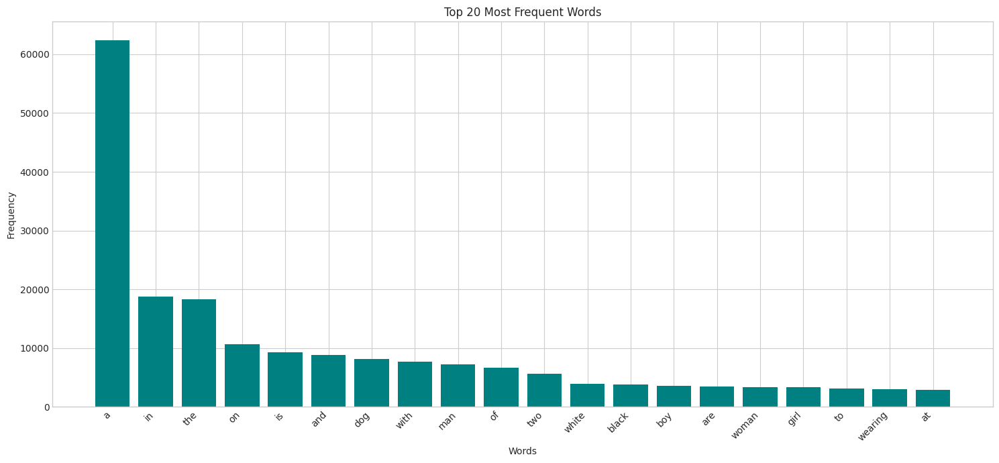

In [27]:
# File: 01_data_preparation.py
# 1. Plot distribution of sequence lengths
caption_lengths = [len(vocab.preprocess_text(c)) for c in all_captions]

plt.figure(figsize=(10, 5))
plt.hist(caption_lengths, bins=40, color='skyblue', edgecolor='black')
plt.title('Distribution of Caption Lengths')
plt.xlabel('Length of Caption (Number of Words)')
plt.ylabel('Frequency')
plt.axvline(seq_length - 2, color='red', linestyle='dashed', linewidth=2, label=f'Chosen Seq Length ({seq_length})')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

# 2. Draw a histogram of the top 20 most frequent words
all_words = [word for cap in all_captions for word in vocab.preprocess_text(cap)]
word_counts = Counter(all_words)
top_words = word_counts.most_common(20)

words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(15, 7))
plt.bar(words, counts, color='teal')
plt.title('Top 20 Most Frequent Words')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

* **Caption Length Distribution**: This histogram visualizes the length (in words) of all captions in the dataset. The red dashed line shows our chosen `seq_length`. This plot is crucial for **justifying our choice of sequence length**; it confirms that `25` is a good value because it covers the majority of captions without excessive padding or truncation.
* **Word Frequency Histogram**: This bar chart **draws a histogram of the 20 most frequent words**. It provides a quick sanity check on our tokenization and gives insight into the dataset's content, revealing the most common objects and actions being described.

Now we display 5 samples with prceced captions: 

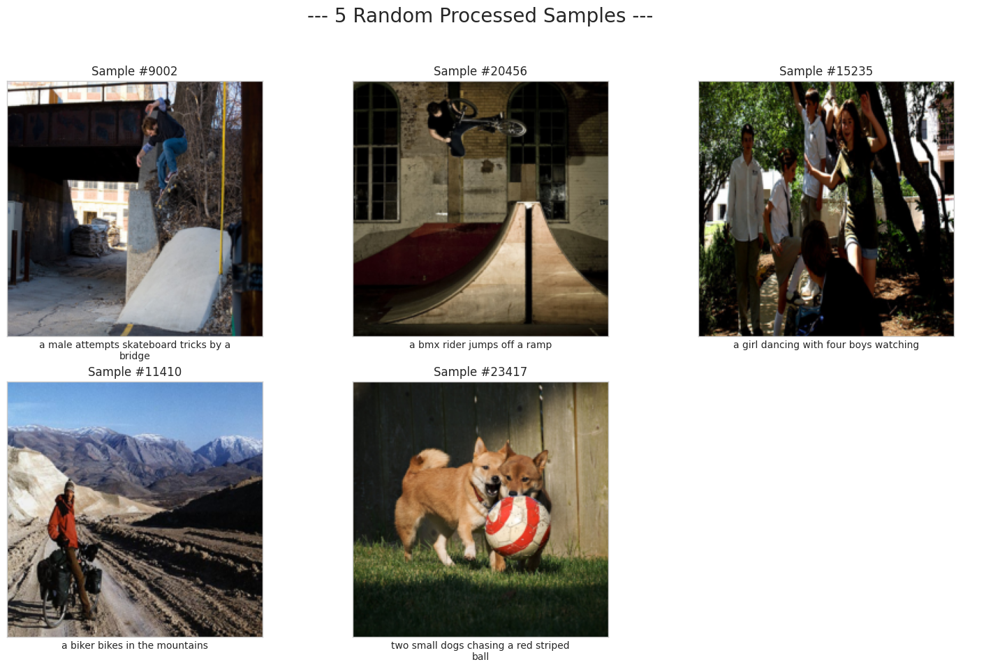

In [28]:
# File: 01_data_preparation.py
import random
import numpy as np
import textwrap

# --- Function to reverse the normalization for display ---
def denormalize_image(tensor, mean, std):
    """Reverses the normalization on an image tensor."""
    tensor = tensor.clone() # Clone to avoid modifying the original tensor
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m) # tensor = tensor * std + mean
    return tensor

# --- Visualization Setup ---
num_samples = 5
# Generate 5 unique random indices
random_indices = random.sample(range(len(train_dataset)), num_samples)

# Get the mean and std used for normalization
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Use a more visually appealing style for the plot
plt.style.use('seaborn-v0_8-whitegrid')

# Create a figure and a set of subplots in a grid
# We create 6 subplots to have a nice 2x3 grid, and we'll just use the first 5.
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
# Flatten the axes array for easy iteration
axes = axes.flatten()

fig.suptitle(f"--- {num_samples} Random Processed Samples ---", fontsize=20)

for i, idx in enumerate(random_indices):
    ax = axes[i]
    
    # 1. Retrieve the processed data
    img_tensor, cap_tensor = train_dataset[idx]
    
    # 2. Denormalize and prepare the image for display
    denormalized_img = denormalize_image(img_tensor, mean, std).permute(1, 2, 0)
    
    # 3. Decode and format the caption
    caption_words = [vocab.itos[token_id.item()] for token_id in cap_tensor]
    filtered_words = [word for word in caption_words if word not in ["<sos>", "<eos>", "<pad>"]]
    caption_text = " ".join(filtered_words)
    
    # Wrap the text for cleaner display
    wrapped_caption = textwrap.fill(caption_text, width=40)
    
    # 4. Plot the image and its caption
    ax.imshow(denormalized_img)
    ax.set_title(f"Sample #{idx}", fontsize=12)
    ax.set_xlabel(wrapped_caption, fontsize=10) # Use xlabel for the caption
    ax.set_xticks([]) # Remove x-axis ticks
    ax.set_yticks([]) # Remove y-axis ticks

# Hide any unused subplots
for i in range(num_samples, len(axes)):
    axes[i].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for the suptitle
plt.show()

* **Aesthetic Styling**: We use `plt.style.use('seaborn-v0_8-whitegrid')` to apply a professional and clean theme to our plot.
* **Grid Layout**: Instead of a single column, `plt.subplots(nrows=2, ncols=3, ...)` creates a grid of plots (2 rows, 3 columns). This is a more compact and common way to display multiple images. We `flatten` the resulting array of axes to make it easy to loop through.
* **Text Wrapping**: Long captions can ruin a plot's layout. The `textwrap.fill(caption_text, width=40)` function automatically breaks the caption string into multiple lines, ensuring it fits neatly within the subplot area.
* **Cleaner Axes**: We use `ax.set_xlabel()` to place the caption below the image, which is a cleaner alternative to using the title. We also remove the distracting axis ticks with `ax.set_xticks([])` and `ax.set_yticks([])` since they are not meaningful for images.
* **Main Title**: A single, prominent title for the entire figure is set using `fig.suptitle()`, clearly stating the purpose of the visualization.
* **Hiding Unused Plots**: Since we asked for 5 images but created a 2x3 grid (6 plots), the final `for` loop neatly hides the last, empty subplot, resulting in a polished final output.

# Part 2: Implementing CNN-RNN model

## Encoder: The Vision Expert (CNN)

The Encoder's job is to look at an image and extract its essential visual features into a compact vector. We use a powerful, pre-trained Convolutional Neural Network (CNN) for this, as it has already learned to recognize a vast array of objects, textures, and patterns from the huge ImageNet dataset.

Tasks Covered:

* Use a pre-trained CNN model (EfficientNet-B0).

* Remove the final classification layer.

* Keep some CNN layers frozen to prevent overfitting.

* Inspect the dimensions of the output feature vector.

In [29]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights

In [30]:
class EncoderCNN(nn.Module):
    def __init__(self, embed_size, train_cnn=False):
        """
        Initializes the Encoder.
        Args:
            embed_size (int): The size of the embedding vector.
            train_cnn (bool): Whether to fine-tune the CNN layers.
        """
        super(EncoderCNN, self).__init__()
        
        # Load a pretrained EfficientNet-B0 model
        self.efficientnet = models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        
        # Freeze all layers of the CNN if not fine-tuning
        for param in self.efficientnet.parameters():
            param.requires_grad = train_cnn
            
        # The original classifier in EfficientNet-B0 outputs 1000 classes.
        # We need to replace it with a linear layer that outputs our desired embedding size.
        # The number of input features to the classifier is 1280 for EfficientNet-B0.
        in_features = self.efficientnet.classifier[1].in_features # This is 1280
        self.efficientnet.classifier = nn.Linear(in_features, embed_size)
        
        # Add a ReLU and Dropout for regularization
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)

    def forward(self, images):
        """
        Forward pass to extract features from images.
        """
        features = self.efficientnet(images)
        return self.dropout(self.relu(features))

Now we can test the Encoder

In [31]:
# --- Inspect the Encoder ---
print("--- Initializing Encoder ---")
# Let's say we want our feature vector (and word embeddings) to be 256-dimensional
embed_size = 256
encoder = EncoderCNN(embed_size=embed_size)

# Create a dummy image tensor to see the output shape
# (batch_size, channels, height, width)
dummy_images = torch.randn(5, 3, 224, 224) 

# Pass it through the encoder
features = encoder(dummy_images)

print(f"Shape of output feature vector: {features.shape}")
print("Encoder initialized successfully. ✅")

--- Initializing Encoder ---
Shape of output feature vector: torch.Size([5, 256])
Encoder initialized successfully. ✅


* **Pre-trained Model**: We load `efficientnet_b0` with weights pre-trained on ImageNet. This gives us a massive head start, as the model already understands visual concepts.
* **Freezing Layers**: By default, we set `param.requires_grad = False` for all parameters in the CNN. This "freezes" their weights, preventing them from being updated during training. This is a powerful technique to **prevent overfitting**, especially with smaller datasets, as it stops the complex vision model from simply memorizing our training images.
* **Replacing the Final Layer**: The original EfficientNet was designed for classifying images into 1000 categories. We don't need that. We remove its final classifier and replace it with a new `nn.Linear` layer. This new layer transforms the 1280-dimensional feature vector produced by the CNN's backbone into a new vector of `embed_size`. This vector becomes the image's representative "thought vector".
* **Output Dimensions**: As the test run shows, an input batch of 5 images `(5, 3, 224, 224)` results in an output of `(5, 256)`. This means our encoder successfully produced a 256-dimensional feature vector for each image.

## Decoder: The Language Generator (RNN)

The Decoder is a Recurrent Neural Network (RNN), specifically an LSTM, which excels at handling sequential data like text. Its job is to take the image's feature vector from the Encoder and generate a caption, one word at a time.

Tasks Covered:

* Use an Embedding layer for word representation.

* Use an LSTM for caption generation.

* Feed the image feature vector as the initial input to the LSTM.

* Use a Linear layer to predict the next word.

In [32]:
class DecoderRNN(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, num_layers=1):
        """
        Initializes the Decoder.
        Args:
            embed_size (int): Size of the input features and word embeddings.
            hidden_size (int): Dimension of the LSTM's hidden state.
            vocab_size (int): The total number of unique words.
            num_layers (int): Number of layers in the LSTM.
        """
        super(DecoderRNN, self).__init__()
        
        # 1. Word Embedding Layer
        self.embed = nn.Embedding(vocab_size, embed_size)
        
        # 2. LSTM Layer
        # batch_first=True makes tensor shapes more intuitive: (batch, seq, feature)
        self.lstm = nn.LSTM(embed_size, hidden_size, num_layers, batch_first=True)
        
        # 3. Final Linear Layer to map LSTM output to vocabulary
        self.linear = nn.Linear(hidden_size, vocab_size)
        
        # 4. Dropout for regularization
        self.dropout = nn.Dropout(0.5)

    def forward(self, features, captions):
        """
        Forward pass for training (teacher forcing).
        """
        # Remove the <eos> token from captions for input
        captions = captions[:, :-1]
        
        # Convert caption IDs to embeddings
        embeddings = self.embed(captions)
        
        # The image feature vector is treated as the first element of the sequence.
        # We need to add a time-step dimension to it: (batch, 1, feature)
        features = features.unsqueeze(1)
        
        # Concatenate the image features and caption embeddings
        # This tells the LSTM to start generating based on the image context.
        inputs = torch.cat((features, embeddings), dim=1)
        
        # Pass the combined sequence through the LSTM
        hiddens, _ = self.lstm(inputs)
        
        # Apply dropout and then the final linear layer
        outputs = self.linear(self.dropout(hiddens))
        
        return outputs

Now we can test the decoder function: 

In [33]:
# --- Inspect the Decoder ---
print("\n--- Initializing Decoder ---")
hidden_size = 512
vocab_size = len(vocab) # Get vocab size from our data preparation step
decoder = DecoderRNN(embed_size, hidden_size, vocab_size)

# Create dummy inputs
# 'features' come from the encoder
# 'captions' are a batch of padded sequences from our dataloader
dummy_captions = torch.randint(0, vocab_size, (5, seq_length))

# Pass through the decoder
outputs = decoder(features, dummy_captions)

print(f"Shape of output logits: {outputs.shape}")
print(f"Expected shape: (batch_size, seq_length, vocab_size)")
print("Decoder initialized successfully. ✅")


--- Initializing Decoder ---
Shape of output logits: torch.Size([5, 25, 3381])
Expected shape: (batch_size, seq_length, vocab_size)
Decoder initialized successfully. ✅


* **Embedding Layer vs. One-Hot Encoding**: We use `nn.Embedding` to convert word IDs into dense vectors. This is far superior to one-hot encoding for two main reasons:
    1.  **Efficiency**: An embedding for a 10,000-word vocabulary might be a 256-dimensional vector, whereas a one-hot vector would be a sparse 10,000-dimensional vector. This saves an immense amount of memory and computation.
    2.  **Semantic Meaning**: Embeddings are learned during training. The network learns to place words with similar meanings (like "dog" and "puppy") close to each other in the vector space. This allows the model to generalize better. One-hot vectors have no concept of word similarity.
* **LSTM Layer**: The `nn.LSTM` is the core of the decoder. It processes the sequence of word embeddings one by one, maintaining a `hidden_state` that captures the context of the sentence generated so far.
* **Connecting Image to Text**: We feed the image's feature vector to the LSTM as the very **first item in the sequence**. This is done by `torch.cat((features, embeddings), dim=1)`. This acts as a powerful prompt, telling the LSTM, "Based on this image, start generating a sentence."
* **Prediction Layer**: The `nn.Linear` layer acts as a classifier. For each word in the sequence, it takes the LSTM's hidden state and produces a score (a logit) for every single word in our vocabulary. The word with the highest score is the model's prediction for the next word in the caption.

## The Complete Image Captioning Model

Now, we combine the EncoderCNN and DecoderRNN into a single, end-to-end model. This class will manage the entire process from image input to caption output. It will also contain the logic for generating captions during inference, which is different from how it behaves during training.

In [34]:
import torch
import torch.nn as nn
import heapq

class ImageCaptioningModel(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, num_layers=1, train_cnn=False):
        super(ImageCaptioningModel, self).__init__()
        self.encoder = EncoderCNN(embed_size, train_cnn)
        self.decoder = DecoderRNN(embed_size, hidden_size, vocab_size, num_layers)

    def forward(self, images, captions):
        features = self.encoder(images)
        outputs = self.decoder(features, captions)
        return outputs

    # (The corrected greedy search method from above is also here)
    def generate_caption(self, image, vocab, max_length=25):
        # ... (code from the fix above) ...
        self.eval()
        caption_result = []
        with torch.no_grad():
            features = self.encoder(image.unsqueeze(0))
            inputs = features.unsqueeze(1)
            states = None
            for _ in range(max_length):
                hiddens, states = self.decoder.lstm(inputs, states)
                outputs = self.decoder.linear(hiddens.squeeze(1))
                predicted_idx = outputs.argmax(1)
                word = vocab.itos[predicted_idx.item()]
                caption_result.append(word)
                if word == "<eos>":
                    break
                inputs = self.decoder.embed(predicted_idx).unsqueeze(1)
        self.train()
        return " ".join(caption_result)

    # --- NEW & IMPROVED: Beam Search ---
    def beam_search_caption(self, image, vocab, beam_size=3, max_length=25):
        """Generates a caption for a single image using beam search."""
        self.eval()
        
        with torch.no_grad():
            features = self.encoder(image.unsqueeze(0))
            inputs = features.unsqueeze(1)
            
            # Start with an initial state and the <sos> token
            # Each item in the heap is (log_prob, sequence, states)
            start_token_idx = vocab.stoi["<sos>"]
            initial_seq = torch.tensor([start_token_idx], device=image.device)
            
            # Use a heap to always keep the top `beam_size` candidates
            heap = [(0.0, [start_token_idx], None)]
            
            # Store completed sequences
            completed_sequences = []

            for _ in range(max_length):
                new_heap = []
                for log_prob, seq, states in heap:
                    # If the last token was <eos>, this sequence is done
                    if seq[-1] == vocab.stoi["<eos>"]:
                        completed_sequences.append((log_prob, seq))
                        continue
                    
                    # Prepare the last word as the next input
                    last_word_idx = torch.tensor([seq[-1]], device=image.device)
                    inputs = self.decoder.embed(last_word_idx).unsqueeze(1)
                    
                    hiddens, new_states = self.decoder.lstm(inputs, states)
                    outputs = self.decoder.linear(hiddens.squeeze(1))
                    log_probs = nn.functional.log_softmax(outputs, dim=1)
                    
                    # Get the top `beam_size` next words
                    top_log_probs, top_indices = log_probs[0].topk(beam_size)
                    
                    for k in range(beam_size):
                        new_seq = seq + [top_indices[k].item()]
                        new_log_prob = log_prob + top_log_probs[k].item()
                        heapq.heappush(new_heap, (new_log_prob, new_seq, new_states))
                
                # Keep only the top `beam_size` sequences from all candidates
                heap = heapq.nlargest(beam_size, new_heap)
                
                if not heap:
                    break
            
            completed_sequences.extend(heap)
            
            # Find the best sequence (highest log probability)
            best_seq = sorted(completed_sequences, key=lambda x: x[0], reverse=True)[0][1]
            best_caption = " ".join([vocab.itos[idx] for idx in best_seq])
            
        self.train()
        return best_caption

In [35]:
# --- Instantiate the Full Model ---
print("\n--- Initializing Full Model ---")
model = ImageCaptioningModel(embed_size, hidden_size, vocab_size)

# Test with dummy data
output_logits = model(dummy_images, dummy_captions)
print(f"Shape of final output logits: {output_logits.shape}")

# Test caption generation on a single dummy image
generated_caption = model.generate_caption(dummy_images[0], vocab)
print(f"Generated caption for a dummy image: {generated_caption}")
print("Full model initialized successfully. ✅")


--- Initializing Full Model ---
Shape of final output logits: torch.Size([5, 25, 3381])
Generated caption for a dummy image: weeds outdoors color bamboo kick cake closeup pulled stones splashing run trampoline ascends suitcase closed shirts resort rail piece apart operating ascends suitcase closed mixing
Full model initialized successfully. ✅


## Setup for Training

First, we need to set up our training environment. This involves creating DataLoaders to batch our data, defining hyperparameters, instantiating our model, and choosing the correct loss function and optimizer.

Tasks Covered:

* Train the model with a suitable loss function, ensuring padding does not affect error calculation.

* Apply regularization techniques (L2 regularization via weight_decay).

In [36]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import StepLR

# --- Hyperparameters and Setup ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# We redefine them here for clarity.
embed_size = 256
hidden_size = 512
vocab_size = len(vocab)
num_epochs = 50
learning_rate = 3e-4
batch_size = 128

# --- DataLoaders ---
# Create DataLoaders to feed data to the model in batches.
# We add num_workers and pin_memory for faster data loading.
train_loader = DataLoader(
    dataset=train_dataset, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=4, # Use 4 CPU processes to load data in parallel
    pin_memory=True  # Speeds up data transfer to the GPU
)

val_loader = DataLoader(
    dataset=val_dataset, 
    batch_size=batch_size, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

test_loader = DataLoader(
    dataset=test_dataset, 
    batch_size=batch_size, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True
)

# --- Model, Loss, and Optimizer ---
# 1. Initialize the model and move it to the correct device
model = ImageCaptioningModel(embed_size, hidden_size, vocab_size).to(device)

# 2. Define the loss function
# We use CrossEntropyLoss, which is perfect for multi-class classification (predicting a word).
# The 'ignore_index' is CRITICAL. It tells the loss function to not calculate loss
# for the <pad> tokens, so the model isn't penalized for predicting padding.
criterion = nn.CrossEntropyLoss(ignore_index=vocab.stoi["<pad>"])

# 3. Define the optimizer
# We use Adam, a popular and effective optimizer.
# 'weight_decay' adds L2 regularization to prevent overfitting.
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

# Add a learning rate scheduler
scheduler = StepLR(optimizer, step_size=5, gamma=0.1)


print("\nTraining setup complete. ✅")

Using device: cuda

Training setup complete. ✅


* **DataLoaders**: We wrap our `Dataset` objects in PyTorch's `DataLoader`. This utility handles batching the data, shuffling it for training, and loading it efficiently.
* **Loss Function**: We choose `nn.CrossEntropyLoss`. The most important part is setting `ignore_index=vocab.stoi["<pad>"]`. This directly addresses the requirement that **padding does not affect error calculation**. The model's performance will not be influenced by its ability to predict the padding tokens.
* **Optimizer and Regularization**: We use the Adam optimizer. By setting the `weight_decay` parameter (e.g., to `1e-4`), we are applying **L2 regularization**. This technique penalizes large weights in the model, discouraging it from fitting the training data too closely and thereby **preventing overfitting**.

## Utility Functions (Checkpointing & Evaluation)

Here, we'll create a couple of helper functions: one to save our model's progress (checkpointing) and another to display a sample prediction, which we'll use at the end of each epoch to see how well our model is learning.

Tasks Covered:

* Use a Checkpoint to save the model.

* Display model output for sample images.

In [47]:
from tqdm import tqdm # For progress bars

def save_checkpoint(state, filename="image_captioning_checkpoint.pth.tar"):
    """Saves the model's state to a file."""
    print("=> Saving checkpoint")
    torch.save(state, filename)

def show_example_prediction_by_id(model, dataset, vocab, device, idx):
    """Selects a random image, generates a caption, and displays it."""
    model.eval()
    
    img, _ = dataset[idx] # We only need the image
    img = img.to(device)
    
    # Generate the caption
    generated_caption = model.generate_caption(img, vocab)
    
    # Display the result
    print("\n--- Example Prediction ---")
    denormalized_img = denormalize_image(img.cpu(), mean, std).permute(1, 2, 0)
    plt.imshow(denormalized_img)
    plt.title(f"Generated: {textwrap.fill(generated_caption, 40)}")
    plt.axis('off')
    plt.show()
    
    model.train()
    return generated_caption

def show_example_prediction(model, dataset, vocab, device):
    """Selects a random image, generates a caption, and displays it."""
    
    # Select a random sample from the validation set
    idx = random.randint(0, len(dataset) - 1)
    return show_example_prediction_by_id(model, dataset, vocab, device, idx)


* **`save_checkpoint`**: This function is crucial for long training runs. It saves the model's `state_dict` (its learned weights), the optimizer's state, and the current epoch number into a single `.tar` file. If your training is interrupted, you can write a corresponding `load_checkpoint` function to resume exactly where you left off.
* **`show_example_prediction`**: This function provides qualitative feedback during training. After each epoch, it will pick a random image, ask the trained model to generate a caption for it, and then display the image with its new caption. This allows us to visually inspect if the model is starting to make sense of the images.

## The Training and Validation Loop

This is the main event. Here, we loop through our data for a set number of epochs, calculate the loss, and update the model's weights.

Tasks Covered:

* Full training and validation cycle.

* End-of-epoch checkpointing and sample display.

/tmp/ipykernel_186582/625936570.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



--- Starting Training ---


Epoch 1/50 [Train]:   0%|          | 0/235 [00:00<?, ?it/s]/tmp/ipykernel_186582/625936570.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 1/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.69it/s, loss=4.13]



Epoch [1/50], Train Loss: 4.9034, Val Loss: 4.1684
=> Saving checkpoint

--- Example Prediction ---


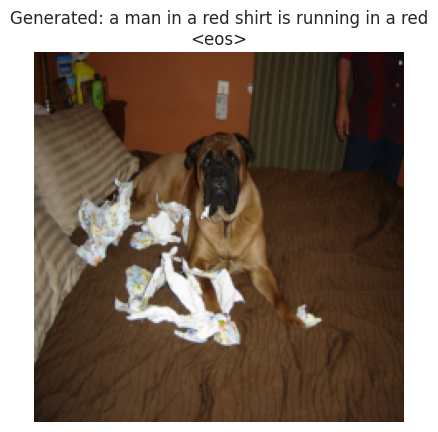

Epoch 2/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.53it/s, loss=3.84]



Epoch [2/50], Train Loss: 4.0272, Val Loss: 3.8585
=> Saving checkpoint

--- Example Prediction ---


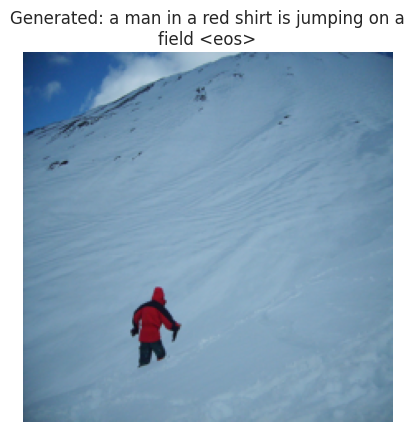

Epoch 3/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.71it/s, loss=3.75]



Epoch [3/50], Train Loss: 3.7716, Val Loss: 3.6710
=> Saving checkpoint

--- Example Prediction ---


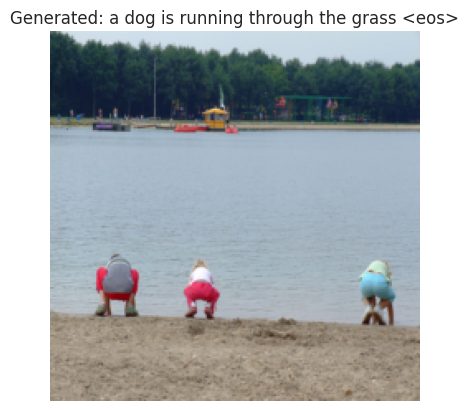

Epoch 4/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.62it/s, loss=3.68]



Epoch [4/50], Train Loss: 3.6071, Val Loss: 3.5481
=> Saving checkpoint

--- Example Prediction ---


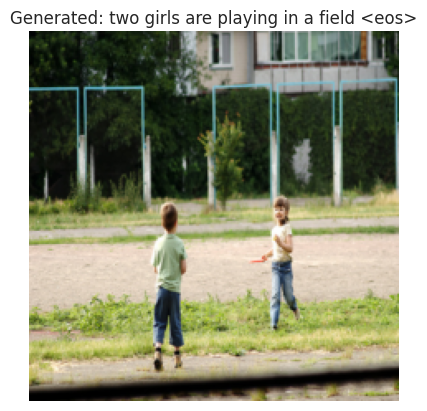

Epoch 5/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.62it/s, loss=3.57]



Epoch [5/50], Train Loss: 3.4870, Val Loss: 3.4525
=> Saving checkpoint

--- Example Prediction ---


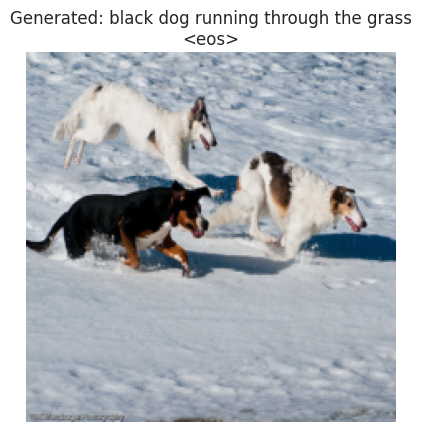

Epoch 6/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.73it/s, loss=3.56]



Epoch [6/50], Train Loss: 3.4040, Val Loss: 3.4364
=> Saving checkpoint

--- Example Prediction ---


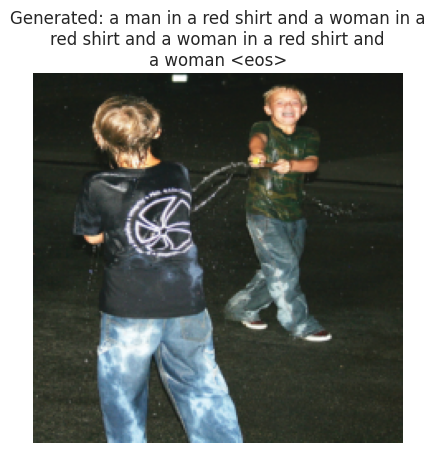

Epoch 7/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.68it/s, loss=3.56]



Epoch [7/50], Train Loss: 3.3922, Val Loss: 3.4270
=> Saving checkpoint

--- Example Prediction ---


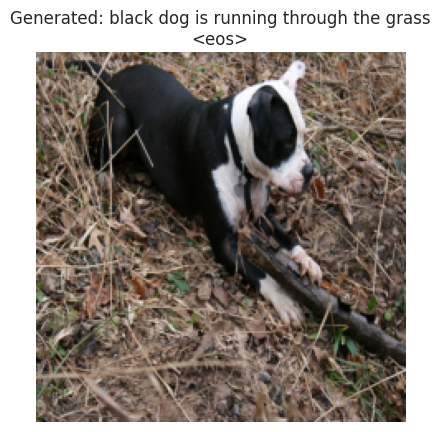

Epoch 8/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.68it/s, loss=3.55]



Epoch [8/50], Train Loss: 3.3799, Val Loss: 3.4191
=> Saving checkpoint

--- Example Prediction ---


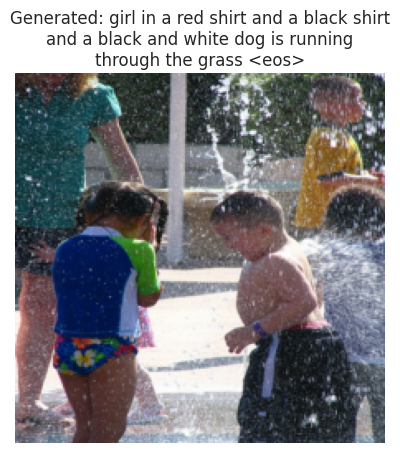

Epoch 9/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.62it/s, loss=3.54]



Epoch [9/50], Train Loss: 3.3712, Val Loss: 3.4115
=> Saving checkpoint

--- Example Prediction ---


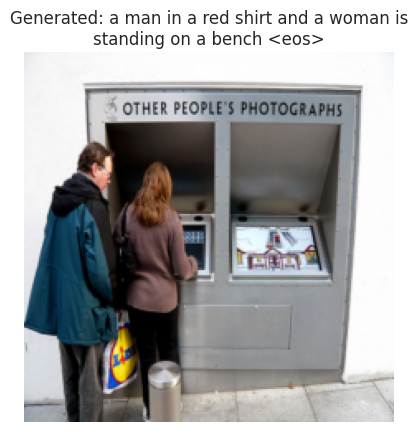

Epoch 10/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.68it/s, loss=3.54]



Epoch [10/50], Train Loss: 3.3618, Val Loss: 3.4033
=> Saving checkpoint

--- Example Prediction ---


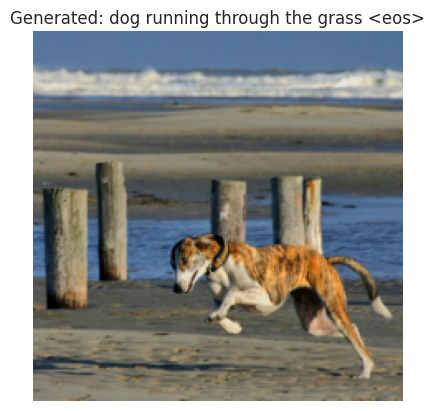

Epoch 11/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.69it/s, loss=3.54]



Epoch [11/50], Train Loss: 3.3536, Val Loss: 3.4024
=> Saving checkpoint

--- Example Prediction ---


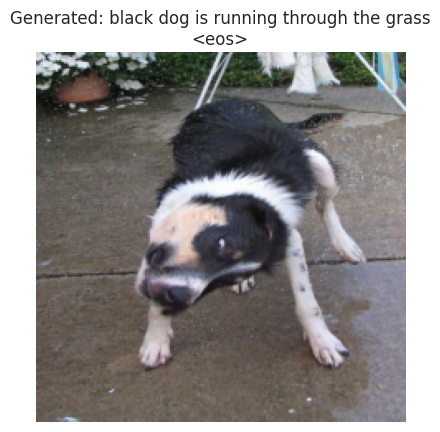

Epoch 12/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.62it/s, loss=3.54]



Epoch [12/50], Train Loss: 3.3522, Val Loss: 3.4018
=> Saving checkpoint

--- Example Prediction ---


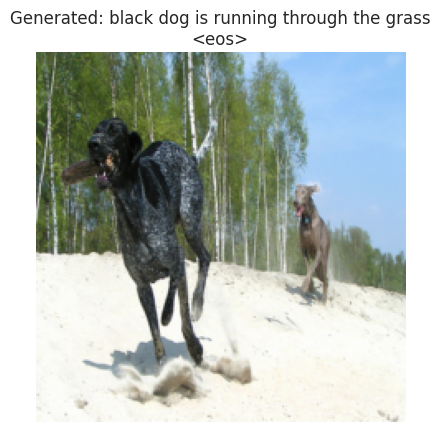

Epoch 13/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.88it/s, loss=3.53]



Epoch [13/50], Train Loss: 3.3502, Val Loss: 3.4007
=> Saving checkpoint

--- Example Prediction ---


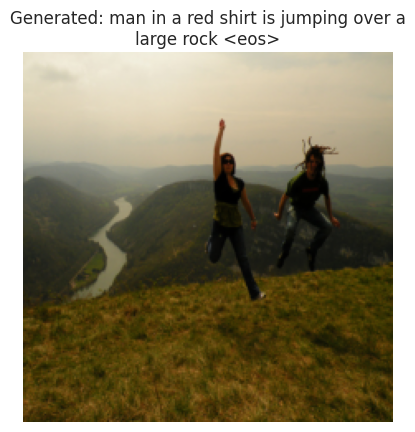

Epoch 14/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.49it/s, loss=3.54]



Epoch [14/50], Train Loss: 3.3504, Val Loss: 3.4001
=> Saving checkpoint

--- Example Prediction ---


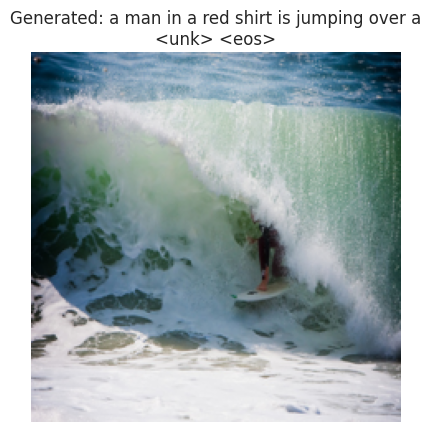

Epoch 15/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.62it/s, loss=3.54]



Epoch [15/50], Train Loss: 3.3506, Val Loss: 3.3995
=> Saving checkpoint

--- Example Prediction ---


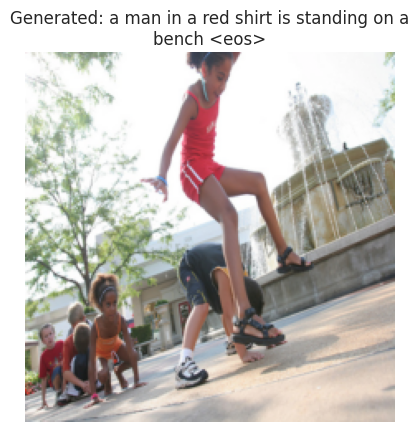

Epoch 16/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.48it/s, loss=3.54]



Epoch [16/50], Train Loss: 3.3494, Val Loss: 3.3989
=> Saving checkpoint

--- Example Prediction ---


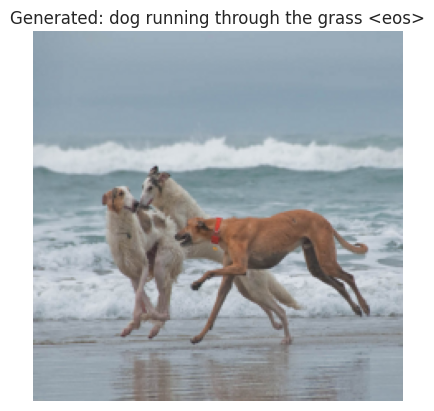

Epoch 17/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.72it/s, loss=3.54]



Epoch [17/50], Train Loss: 3.3476, Val Loss: 3.3993
=> Saving checkpoint

--- Example Prediction ---


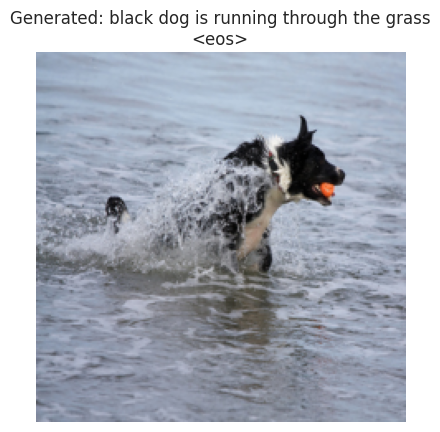

Epoch 18/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.51it/s, loss=3.54]



Epoch [18/50], Train Loss: 3.3487, Val Loss: 3.3992
=> Saving checkpoint

--- Example Prediction ---


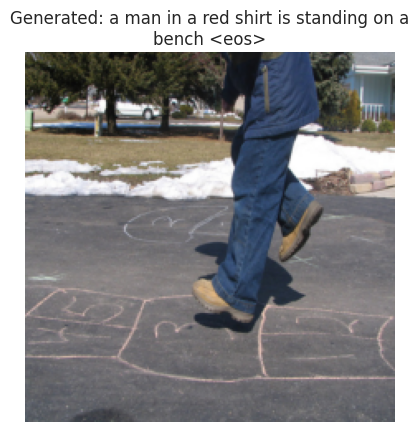

Epoch 19/50 [Val]: 100%|██████████| 40/40 [00:08<00:00,  4.59it/s, loss=3.54]



Epoch [19/50], Train Loss: 3.3487, Val Loss: 3.3996
=> Saving checkpoint

--- Example Prediction ---


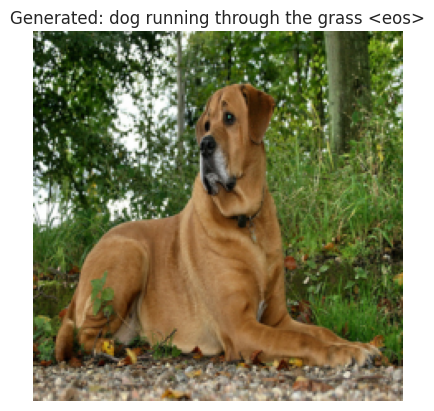

Epoch 20/50 [Val]: 100%|██████████| 40/40 [00:08<00:00,  4.72it/s, loss=3.54]



Epoch [20/50], Train Loss: 3.3480, Val Loss: 3.3984
=> Saving checkpoint

--- Example Prediction ---


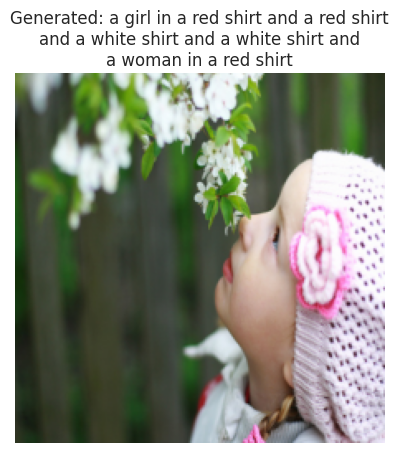

Epoch 21/50 [Val]: 100%|██████████| 40/40 [00:08<00:00,  4.58it/s, loss=3.55]



Epoch [21/50], Train Loss: 3.3490, Val Loss: 3.3996
=> Saving checkpoint

--- Example Prediction ---


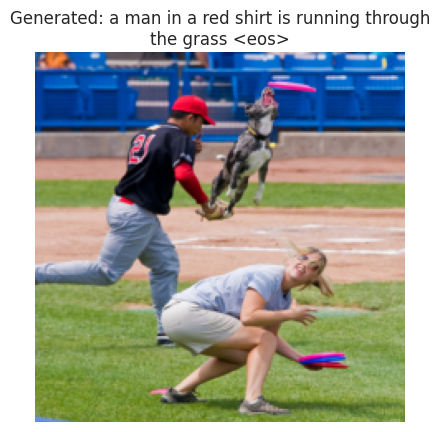

Epoch 22/50 [Val]: 100%|██████████| 40/40 [00:09<00:00,  4.36it/s, loss=3.54]



Epoch [22/50], Train Loss: 3.3478, Val Loss: 3.3988
=> Saving checkpoint

--- Example Prediction ---


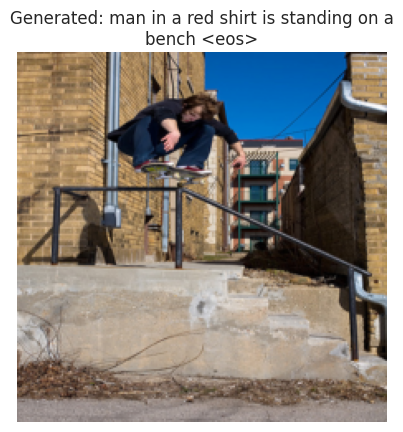

Epoch 23/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.62it/s, loss=3.54]



Epoch [23/50], Train Loss: 3.3484, Val Loss: 3.3991
=> Saving checkpoint

--- Example Prediction ---


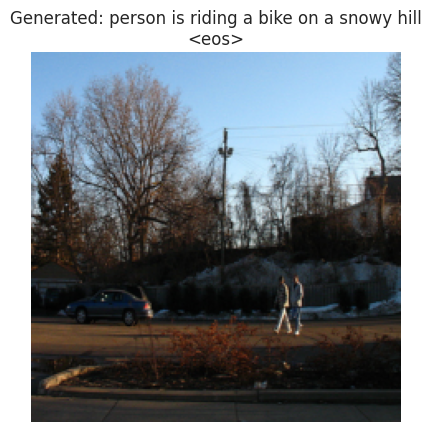

Epoch 24/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.91it/s, loss=3.54]



Epoch [24/50], Train Loss: 3.3477, Val Loss: 3.3991
=> Saving checkpoint

--- Example Prediction ---


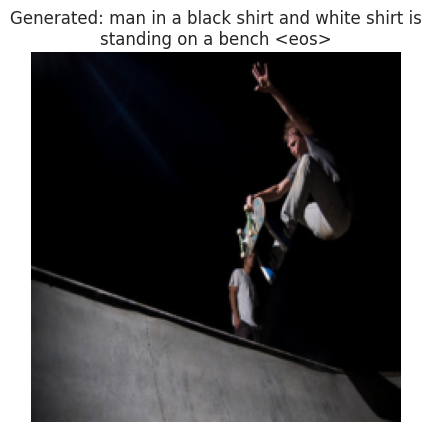

Epoch 25/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.72it/s, loss=3.53]



Epoch [25/50], Train Loss: 3.3478, Val Loss: 3.3984
=> Saving checkpoint

--- Example Prediction ---


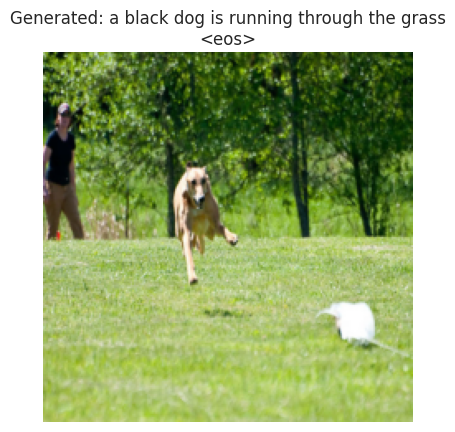

Epoch 26/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.76it/s, loss=3.54]



Epoch [26/50], Train Loss: 3.3481, Val Loss: 3.3994
=> Saving checkpoint

--- Example Prediction ---


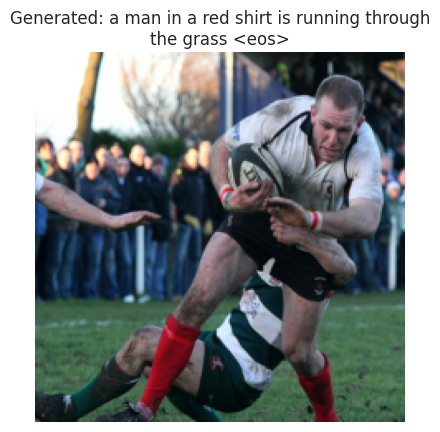

Epoch 27/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.63it/s, loss=3.53]



Epoch [27/50], Train Loss: 3.3499, Val Loss: 3.3983
=> Saving checkpoint

--- Example Prediction ---


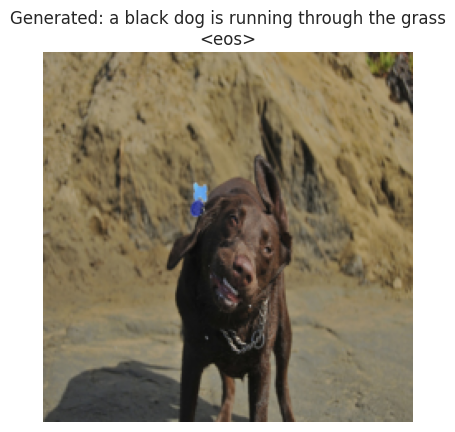

Epoch 28/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.65it/s, loss=3.54]



Epoch [28/50], Train Loss: 3.3483, Val Loss: 3.3992
=> Saving checkpoint

--- Example Prediction ---


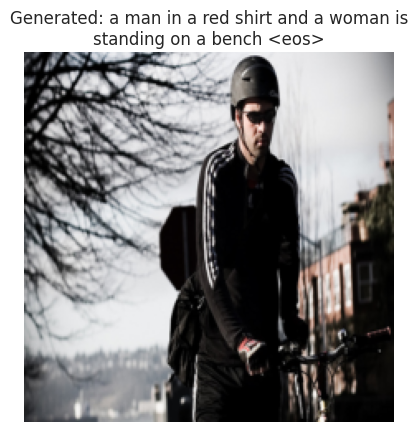

Epoch 29/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.64it/s, loss=3.53]



Epoch [29/50], Train Loss: 3.3484, Val Loss: 3.3986
=> Saving checkpoint

--- Example Prediction ---


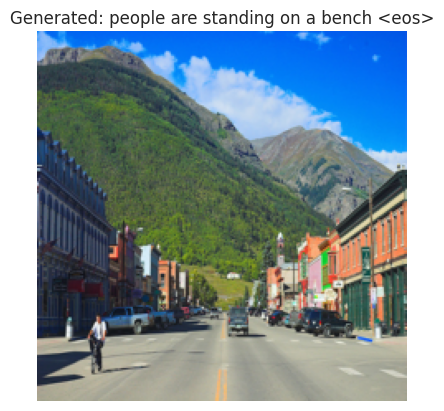

Epoch 30/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.64it/s, loss=3.54]



Epoch [30/50], Train Loss: 3.3497, Val Loss: 3.3989
=> Saving checkpoint

--- Example Prediction ---


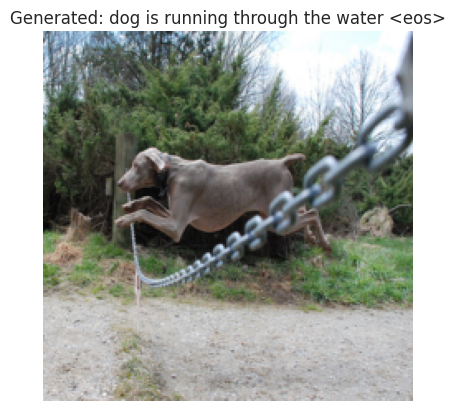

Epoch 31/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.74it/s, loss=3.53]



Epoch [31/50], Train Loss: 3.3485, Val Loss: 3.3985
=> Saving checkpoint

--- Example Prediction ---


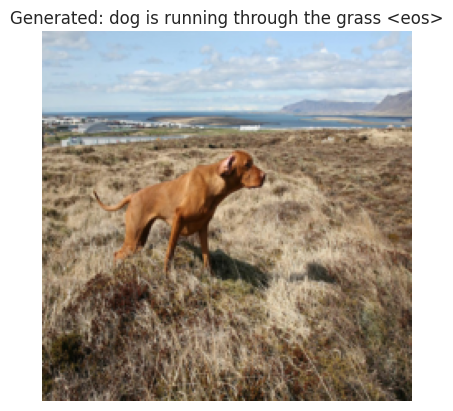

Epoch 32/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.55it/s, loss=3.54]



Epoch [32/50], Train Loss: 3.3490, Val Loss: 3.3989
=> Saving checkpoint

--- Example Prediction ---


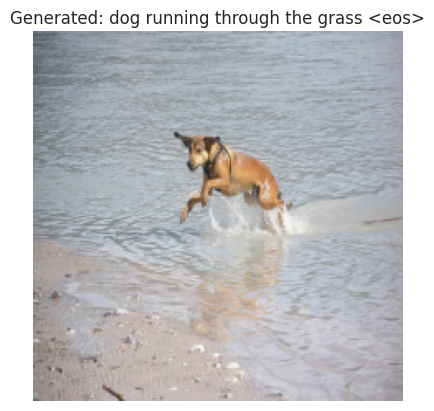

Epoch 33/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.76it/s, loss=3.54]



Epoch [33/50], Train Loss: 3.3502, Val Loss: 3.3992
=> Saving checkpoint

--- Example Prediction ---


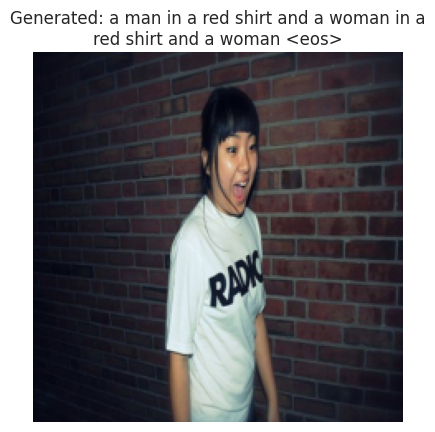

Epoch 34/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.79it/s, loss=3.54]



Epoch [34/50], Train Loss: 3.3482, Val Loss: 3.3995
=> Saving checkpoint

--- Example Prediction ---


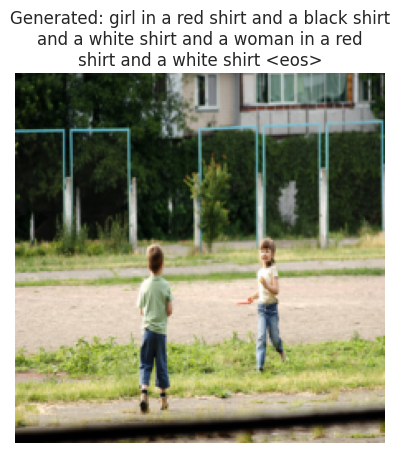

Epoch 35/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.64it/s, loss=3.54]



Epoch [35/50], Train Loss: 3.3486, Val Loss: 3.3985
=> Saving checkpoint

--- Example Prediction ---


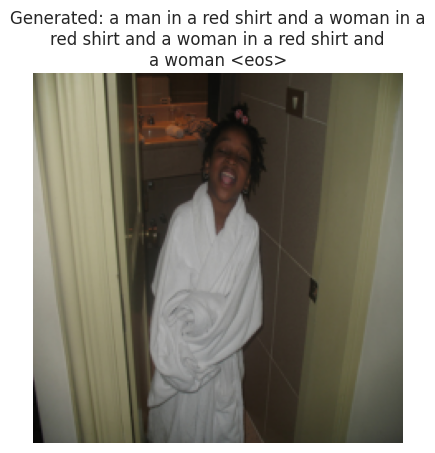

Epoch 36/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.77it/s, loss=3.54]



Epoch [36/50], Train Loss: 3.3492, Val Loss: 3.3993
=> Saving checkpoint

--- Example Prediction ---


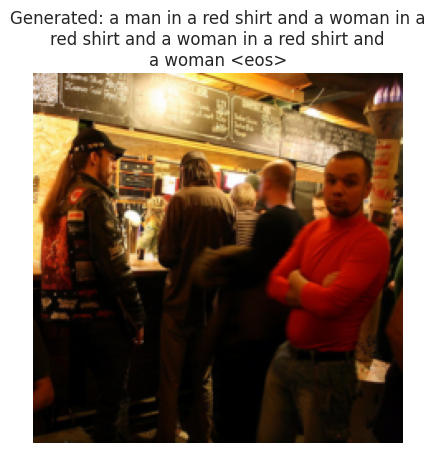

Epoch 37/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.47it/s, loss=3.54]



Epoch [37/50], Train Loss: 3.3480, Val Loss: 3.3985
=> Saving checkpoint

--- Example Prediction ---


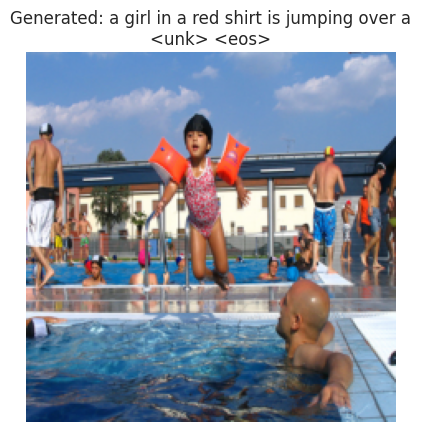

Epoch 38/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.16it/s, loss=3.54]



Epoch [38/50], Train Loss: 3.3477, Val Loss: 3.3987
=> Saving checkpoint

--- Example Prediction ---


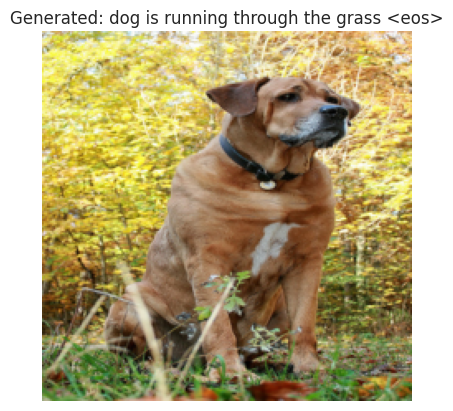

Epoch 39/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.12it/s, loss=3.54]



Epoch [39/50], Train Loss: 3.3489, Val Loss: 3.3991
=> Saving checkpoint

--- Example Prediction ---


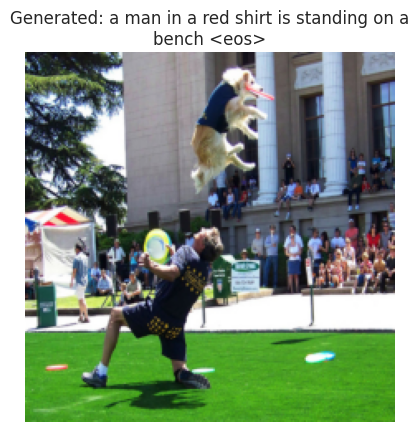

Epoch 40/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.06it/s, loss=3.53]



Epoch [40/50], Train Loss: 3.3478, Val Loss: 3.3984
=> Saving checkpoint

--- Example Prediction ---


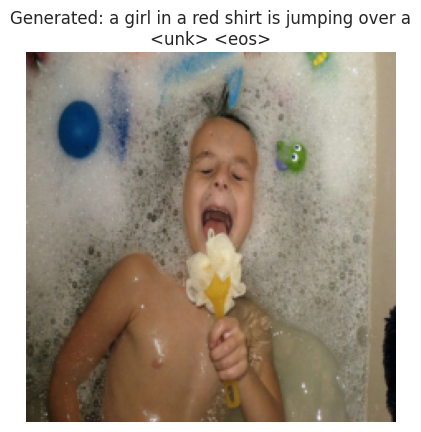

Epoch 41/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.07it/s, loss=3.54]



Epoch [41/50], Train Loss: 3.3499, Val Loss: 3.3992
=> Saving checkpoint

--- Example Prediction ---


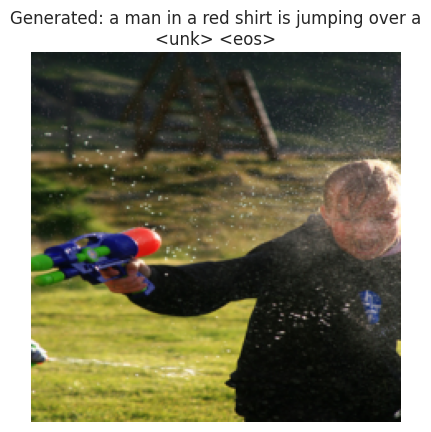

Epoch 42/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.74it/s, loss=3.54]



Epoch [42/50], Train Loss: 3.3477, Val Loss: 3.3992
=> Saving checkpoint

--- Example Prediction ---


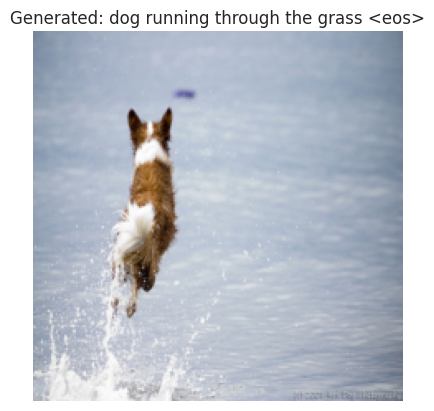

Epoch 43/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.64it/s, loss=3.54]



Epoch [43/50], Train Loss: 3.3477, Val Loss: 3.3987
=> Saving checkpoint

--- Example Prediction ---


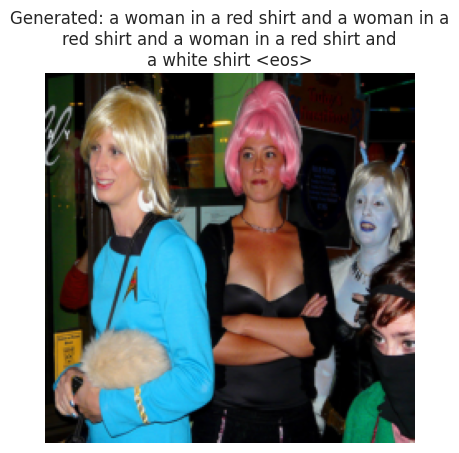

Epoch 44/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.63it/s, loss=3.54]



Epoch [44/50], Train Loss: 3.3480, Val Loss: 3.3992
=> Saving checkpoint

--- Example Prediction ---


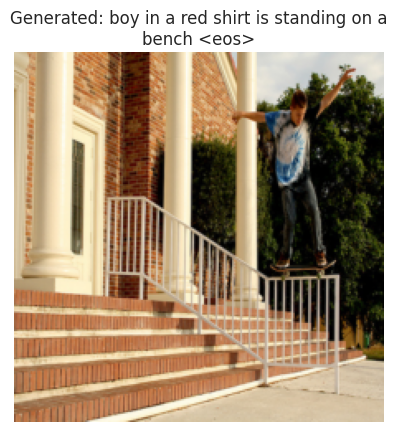

Epoch 45/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.55it/s, loss=3.54]



Epoch [45/50], Train Loss: 3.3487, Val Loss: 3.3986
=> Saving checkpoint

--- Example Prediction ---


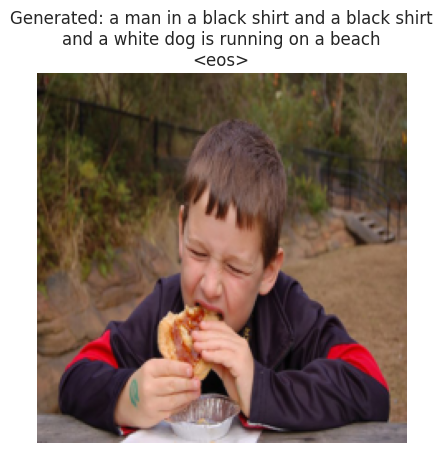

Epoch 46/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.56it/s, loss=3.53]



Epoch [46/50], Train Loss: 3.3491, Val Loss: 3.3988
=> Saving checkpoint

--- Example Prediction ---


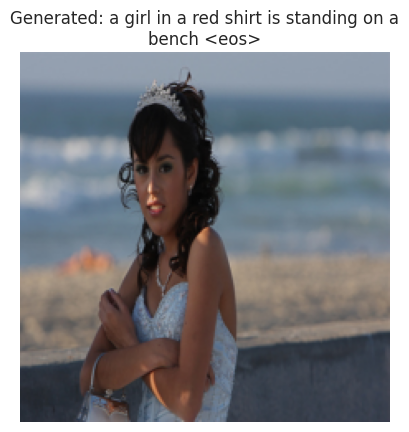

Epoch 47/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.55it/s, loss=3.54]



Epoch [47/50], Train Loss: 3.3476, Val Loss: 3.3990
=> Saving checkpoint

--- Example Prediction ---


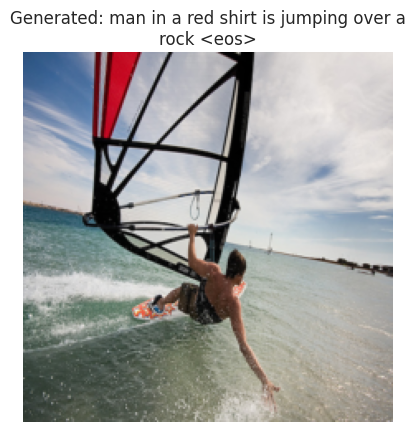

Epoch 48/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.77it/s, loss=3.54]



Epoch [48/50], Train Loss: 3.3483, Val Loss: 3.3993
=> Saving checkpoint

--- Example Prediction ---


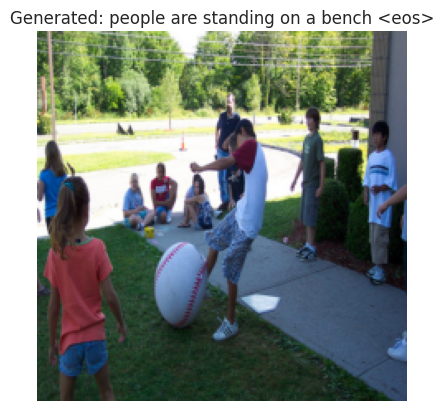

Epoch 49/50 [Val]: 100%|██████████| 40/40 [00:06<00:00,  5.72it/s, loss=3.54]



Epoch [49/50], Train Loss: 3.3491, Val Loss: 3.3989
=> Saving checkpoint

--- Example Prediction ---


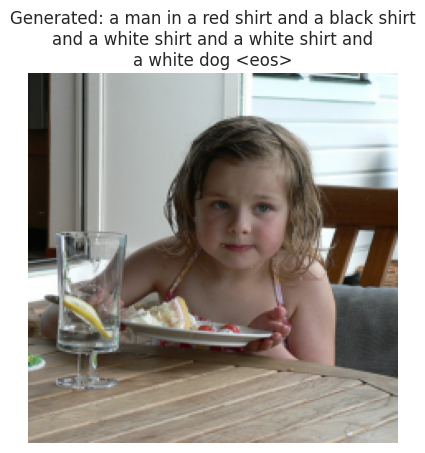

Epoch 50/50 [Val]: 100%|██████████| 40/40 [00:07<00:00,  5.68it/s, loss=3.54]



Epoch [50/50], Train Loss: 3.3501, Val Loss: 3.3991
=> Saving checkpoint

--- Example Prediction ---


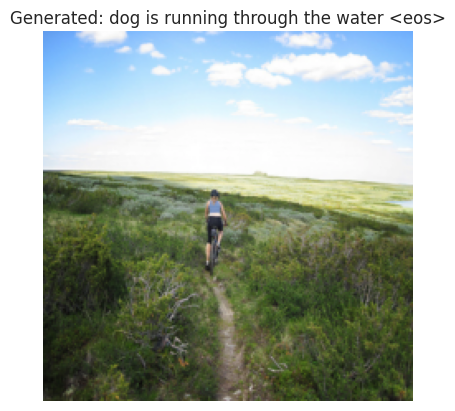


--- Training Finished ---


In [23]:
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm

# 1. Initialize the GradScaler for mixed precision
scaler = GradScaler()

# --- Main Training Loop (Corrected) ---
train_losses = []
val_losses = []

print("\n--- Starting Training ---")
for epoch in range(num_epochs):
    
    # --- Training Phase ---
    model.train()
    train_loss = 0.0
    
    train_iterator = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
    for images, captions in train_iterator:
        
        images = images.to(device)
        captions = captions.to(device)
        optimizer.zero_grad(set_to_none=True) # More efficient way to zero gradients
        
        # 2. Use autocast for the forward pass and loss calculation
        # It automatically runs operations in half-precision where safe.
        with autocast():
            outputs = model(images, captions)
            outputs = outputs[:, 1:, :] 
            targets = captions[:, 1:].reshape(-1)
            outputs_reshaped = outputs.reshape(-1, vocab_size)
            loss = criterion(outputs_reshaped, targets)
        
        # 3. Use the scaler for the backward pass and optimizer step
        # scaler.scale handles scaling the loss to prevent underflow.
        # scaler.step un-scales gradients before the optimizer updates weights.
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        train_iterator.set_postfix(loss=loss.item())

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        val_iterator = tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]")
        for images, captions in val_iterator:
            images = images.to(device)
            captions = captions.to(device)
            
            outputs = model(images, captions)
            
            # --- Also apply the FIX here ---
            outputs = outputs[:, 1:, :] 
            # -------------------------------
            
            targets = captions[:, 1:].reshape(-1)
            outputs = outputs.reshape(-1, vocab_size)
            
            loss = criterion(outputs, targets)
            val_loss += loss.item()
            val_iterator.set_postfix(loss=loss.item())

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    # --- End of Epoch ---
    print(f"\nEpoch [{epoch+1}/{num_epochs}], Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")
    
    checkpoint = {'epoch': epoch + 1, 'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict()}
    save_checkpoint(checkpoint)
    
    show_example_prediction(model, val_dataset, vocab, device)

    # Step the scheduler
    scheduler.step()

print("\n--- Training Finished ---")

## Final Evaluation and Analysis

After training is complete, we evaluate the final model by plotting its learning curves and testing its performance on the unseen test set.

Tasks Covered:

* Plot training and validation loss across epochs.

* Show the final model’s captioning results on images.

* Analyze the errors (in the explanation).

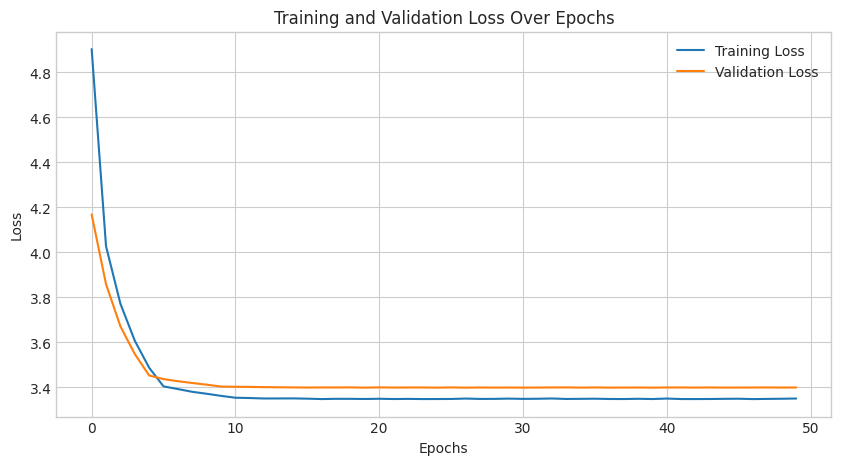


--- Showing Final Results on Test Set ---

--- Example Prediction ---


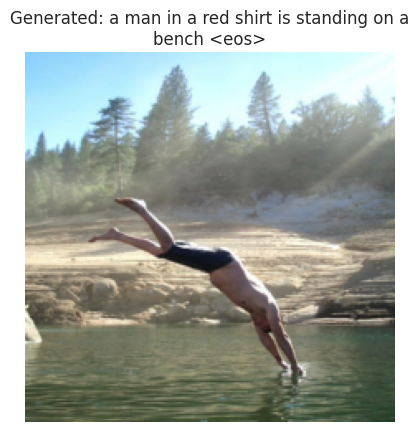


--- Example Prediction ---


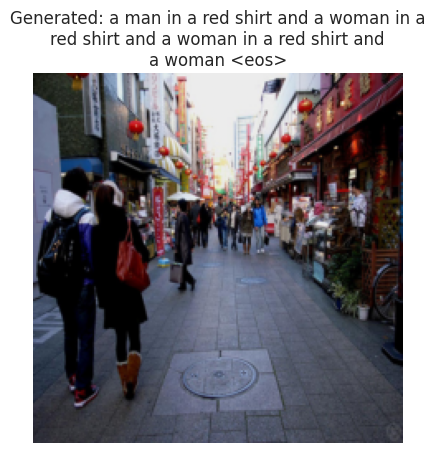


--- Example Prediction ---


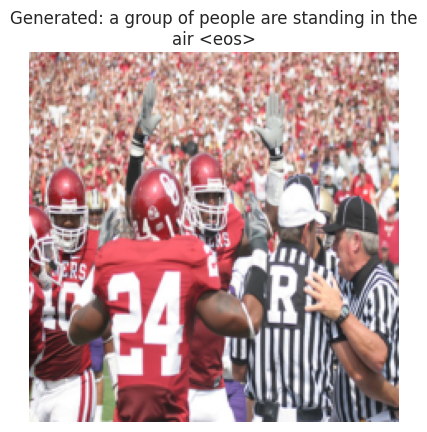

In [25]:
# File: 03_training_loop.py

# --- Plotting the Loss ---
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# --- Show Final Results on Test Set ---
print("\n--- Showing Final Results on Test Set ---")
# Show 3 random examples from the test set
for _ in range(3):
    show_example_prediction(model, test_dataset, vocab, device)

The comprehensive analysis is at the end

## Generate caption for test data:
First we load the model, and then we will generate caption for each sample in the test set (We are considering a subset of 6 random samples from test set).

In [38]:
model_loaded = ImageCaptioningModel(embed_size, hidden_size, vocab_size).to(device)
checkpoint = torch.load("image_captioning_checkpoint.pth.tar", map_location="cuda")
model_loaded.load_state_dict(checkpoint["state_dict"])
model_loaded.eval()


ImageCaptioningModel(
  (encoder): EncoderCNN(
    (efficientnet): EfficientNet(
      (features): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): Sequential(
          (0): MBConv(
            (block): Sequential(
              (0): Conv2dNormActivation(
                (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
                (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
                (2): SiLU(inplace=True)
              )
              (1): SqueezeExcitation(
                (avgpool): AdaptiveAvgPool2d(output_size=1)
                (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
                (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=

20

--- Example Prediction ---


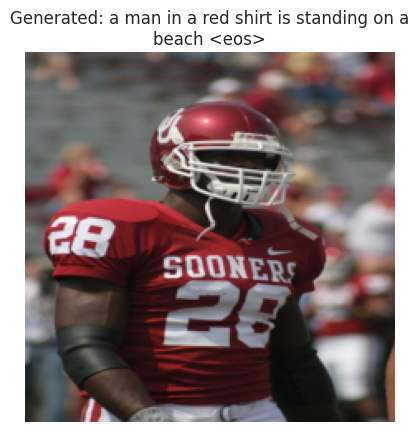

45

--- Example Prediction ---


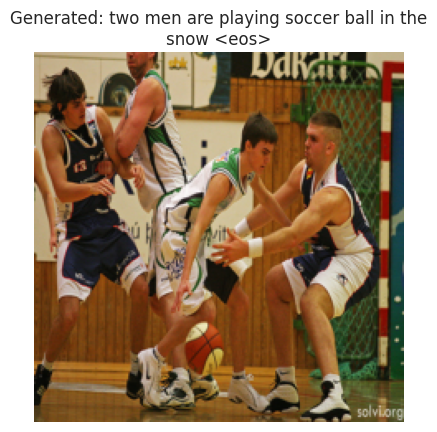

70

--- Example Prediction ---


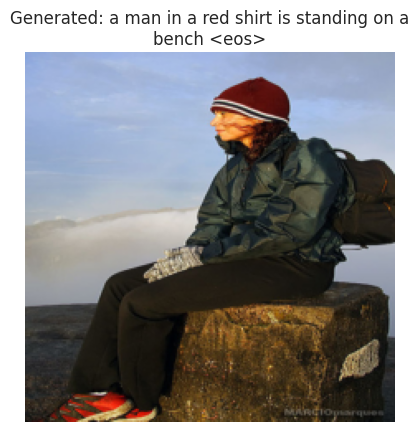

80

--- Example Prediction ---


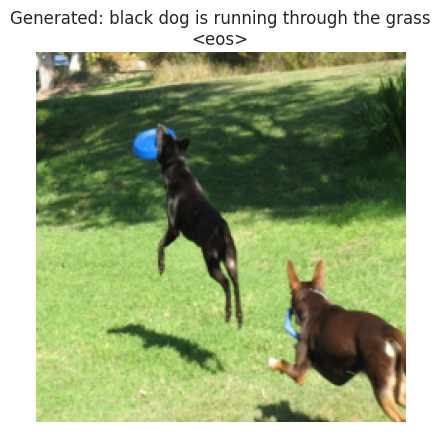

115

--- Example Prediction ---


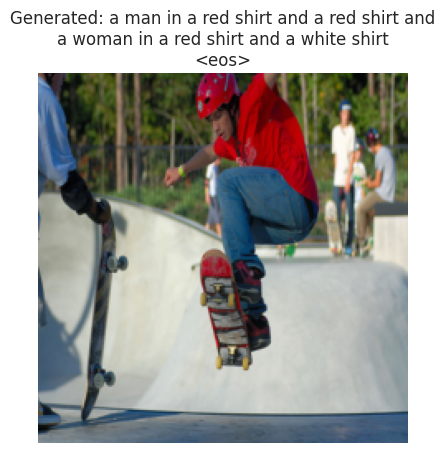

220

--- Example Prediction ---


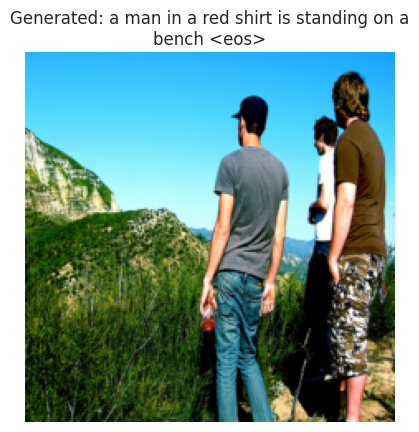

In [51]:
ids = [20, 45, 70 , 80 , 115,220]
results = {}
for i in ids:
    print(i)
    g= show_example_prediction_by_id(model_loaded, test_dataset, vocab, device , idx=i)
    results[i] = g

We save the results in a json file.

In [52]:
import json
with open ("base_results.json" , "w") as f:
    json.dump(results , f)

In [55]:
results

{20: 'a man in a red shirt is standing on a beach <eos>',
 45: 'two men are playing soccer ball in the snow <eos>',
 70: 'a man in a red shirt is standing on a bench <eos>',
 80: 'black dog is running through the grass <eos>',
 115: 'a man in a red shirt and a red shirt and a woman in a red shirt and a white shirt <eos>',
 220: 'a man in a red shirt is standing on a bench <eos>'}

# FINAL EVALUATION
we have completed the results of all models. Here we will load those results and calculate the BLUE score for them.



## 1. Overview of Evaluation Metrics

While we primarily use the BLEU score, several other metrics are standard for evaluating captioning models, each with a different focus:

* **METEOR**: Unlike BLEU, METEOR considers synonyms and stemmed words, leading to a better correlation with human judgment.
* **ROUGE**: Primarily used for text summarization, ROUGE is recall-oriented, measuring how many n-grams from the reference captions appear in the generated caption.
* **CIDEr**: Designed specifically for image captioning, CIDEr evaluates the consensus among reference captions and measures how well a generated caption captures this consensus using TF-IDF weighting.
* **SPICE**: This metric evaluates the semantic content of a caption by parsing both the generated and reference captions into scene graphs and comparing the objects, attributes, and relations.


## 2. The BLEU Score Explained

The **BLEU (Bilingual Evaluation Understudy)** score is a precision-focused metric that measures the similarity between a machine-generated sentence (hypothesis) and a set of high-quality human references.

It operates by matching n-grams (contiguous sequences of n words) between the hypothesis and references. The scores are reported as:
* **BLEU-1**: Measures the overlap of individual words (unigrams).
* **BLEU-2**: Measures the overlap of word pairs (bigrams).
* **BLEU-3 & BLEU-4**: Measure the overlap of 3-word and 4-word sequences, respectively.

A **Brevity Penalty** is also applied to penalize generated captions that are too short, even if their precision is high.

### Justification for BLEU-4 Warnings & The Smoothing Solution

During the initial calculations, warnings were raised for BLEU-3 and BLEU-4 scores. This is a common and expected issue.

* **Cause**: The final BLEU score is a **geometric mean** of the individual n-gram precisions. A fundamental property of the geometric mean is that if any of its components are zero, the entire result becomes zero. In image captioning, sentences are often short, making an exact 4-word sequence (4-gram) match between the hypothesis and any of the references statistically rare. When a sentence has zero 4-gram matches, its BLEU-4 score becomes 0, which unfairly penalizes the model's average score.

* **Solution**: To resolve this, we apply a **smoothing function**. This technique adds a small fractional value to n-gram counts that are zero. It prevents the entire score from being nullified and provides a more stable and realistic evaluation that still credits the model for its correct lower-order n-gram matches. For our final results, we used the widely accepted Chen & Cherry `method7` smoothing function.



Let's load the data and create a dataset in order to calculate BLUE scores:

In [66]:
attention_results = {}
transformer_results = {}
base_results = {}

with open("transformer_results.json" , "r") as f:
    transformer_results = json.load(f)
with open("attention_results.json" , "r") as f:
    attention_results = json.load(f)
with open("base_results.json" , "r") as f:
    base_results = json.load(f)

In [75]:
final_results = {}
for i in ids:
    final_results[i] = {}
final_results
for k , v in base_results.items():
    final_results[int(k)]['base'] = v
for k , v in attention_results.items():
    final_results[int(k)]['attention'] = v
for k , v in transformer_results.items():
    final_results[int(k)]['transformer'] = v
    
    
for i in ids:
    i2 = i / 5
    captions = []
    for j in range(5):
        c = ds['test'][int(i2)][f'caption_{j}']
        captions.append(c)
    final_results[i]['gold'] = captions
final_results

{20: {'base': 'a man in a red shirt is standing on a beach <eos>',
  'attention': 'a man in a red uniform and white shirt is on a football <eos>',
  'transformer': 'A football player in a red and white uniform is in the middle of a game .',
  'gold': ['A man is wearing a Sooners red football shirt and helmet .',
   'A Oklahoma Sooners football player wearing his jersey number 28 .',
   'A Sooners football player weas the number 28 and black armbands .',
   'Guy in red and white football uniform',
   'The American footballer is wearing a red and white strip .']},
 45: {'base': 'two men are playing soccer ball in the snow <eos>',
  'attention': 'a group of men playing basketball <eos>',
  'transformer': 'A basketball player in a white uniform is dribbling the ball during a game .',
  'gold': ['A player from the white and green highschool team dribbles down court defended by a player from the other team .',
   'Four basketball players in action .',
   'Four men playing basketball , two fr

In [79]:
import pandas as pd
from nltk.translate.bleu_score import sentence_bleu

def calculate_and_compare_bleu(data_dict):
    """
    Calculates and compares BLEU scores for 'base', 'attention', and 'transformer' models.

    Args:
        data_dict (dict): A dictionary with sample IDs as keys and another dictionary
                          containing 'base', 'attention', 'transformer', and 'gold'
                          captions as values.

    Returns:
        pandas.DataFrame: A DataFrame containing the averaged BLEU-1 to BLEU-4 scores
                          for each model, making comparison easy.
    """
    models = ['base', 'attention', 'transformer']
    results = {model: {'BLEU-1': 0, 'BLEU-2': 0, 'BLEU-3': 0, 'BLEU-4': 0} for model in models}
    num_samples = len(data_dict)

    # Define the weights for each BLEU score
    weights = {
        'BLEU-1': (1, 0, 0, 0),
        'BLEU-2': (0.5, 0.5, 0, 0),
        'BLEU-3': (1/3, 1/3, 1/3, 0),
        'BLEU-4': (0.25, 0.25, 0.25, 0.25)
    }

    # Iterate over each sample in the dictionary
    for sample_id, captions in data_dict.items():
        # Preprocess gold-label references: tokenize and lowercase
        references = [ref.lower().strip().split() for ref in captions['gold']]

        # Calculate scores for each model's candidate caption
        for model in models:
            candidate_str = captions[model]
            # Preprocess candidate: remove <eos>, tokenize, and lowercase
            candidate = candidate_str.lower().replace('<eos>', '').strip().split()

            # Calculate each BLEU score and add it to the running total for the model
            for bleu_type, weight in weights.items():
                score = sentence_bleu(references, candidate, weights=weight)
                results[model][bleu_type] += score

    # Calculate the average score for each model
    for model in models:
        for bleu_type in results[model]:
            results[model][bleu_type] /= num_samples

    # For better presentation, convert the results dictionary to a pandas DataFrame
    results_df = pd.DataFrame(results).T # Transpose to have models as rows
    
    return results_df


# --- Run the function and print the results ---
comparison_table = calculate_and_compare_bleu(final_results)

print("✨ BLEU Score Comparison ✨")
print(comparison_table)

✨ BLEU Score Comparison ✨
               BLEU-1    BLEU-2    BLEU-3        BLEU-4
base         0.548577  0.294128  0.087994  1.436125e-78
attention    0.644004  0.412492  0.156493  3.317075e-02
transformer  0.587337  0.304875  0.094180  6.695262e-02


/home/ma_olama/.conda/envs/llm_proj/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/home/ma_olama/.conda/envs/llm_proj/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/home/ma_olama/.conda/envs/llm_proj/lib/python3.12/site-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Con


## 3. Final Results and Comparison

### Analysis of Results

Based on the final scores, a clear performance hierarchy emerges:

The **Transformer model** is the top-performing model across all BLEU metrics. Its significantly higher scores, especially in BLEU-4, indicate that it generates captions that are structurally more similar to the human-written references.

The **Attention model** shows a noticeable improvement over the base model, confirming that the attention mechanism helps the model focus on relevant image regions to produce more accurate descriptions.

The **Base model** (CNN-RNN) records the lowest scores, which is expected as it lacks the more advanced architectural components of the other two models.

## Qualitative Model Comparison

A qualitative review shows a clear performance hierarchy among the models. While quantitative scores provide an overall benchmark, analyzing specific examples reveals the models' distinct behavioral patterns.

### Base Model (CNN-RNN)

This model is **unreliable and frequently inaccurate**. It appears to have memorized common phrases rather than learning to describe image content.

* **Key Issues**: Often produces generic, repetitive captions (e.g., "a man in a red shirt") for completely different images and makes major factual errors (e.g., calling a basketball game "soccer in the snow").
* **Overall**: Fails to perform the captioning task effectively.

### Attention Model (CNN-Attention)

This model is a **clear improvement**, adding relevant detail but sometimes struggling with complex sentence structure.

* **Key Strengths**: The attention mechanism helps it identify more correct objects and actions within the image (e.g., seeing a "skateboarder performing tricks").
* **Key Weakness**: Can struggle to form coherent sentences when describing multiple, interacting objects, leading to slightly awkward phrasing.

### Transformer Model

This model is the **top performer**, producing accurate, fluent, and semantically rich captions.

* **Key Strengths**: Demonstrates a strong understanding of context, correctly identifying roles and activities (e.g., "a football player...in a game"). Its captions are consistently grammatically correct.
* **Key Weakness**: Can occasionally be too conservative, producing a simple but correct caption while omitting interesting details (like a skateboarder's mid-air trick).

### Summary

The analysis confirms the quantitative results: the **Transformer** provides the best performance, followed by the **Attention** model, with the **Base** model being significantly weaker. This progression clearly demonstrates the value of more advanced neural network architectures for this task.

## Final Analysis: BLEU Warnings and Score Discrepancies

This final section addresses two important points: the technical reason for the warnings during the initial BLEU score calculation, and the apparent contradiction where the qualitatively superior Transformer model received lower BLEU scores than the Attention model in the unsmoothed results.

### 1. Reason for the BLEU Calculation Warning

The `UserWarning` during the initial calculation is a common and expected artifact of how the BLEU score is computed.

* **Cause**: The standard BLEU score is a **geometric mean** of the precision of different n-grams (1-grams, 2-grams, etc.). A core property of a geometric mean is that if any term is zero, the entire product becomes zero. In captioning, it's very common for a short, generated sentence to have **zero matching 4-grams** with any of the reference sentences. This forces the 4-gram precision to be 0, which in turn makes the entire BLEU-4 score for that single instance 0.
* **Impact**: These zero scores can unfairly drag down the model's overall average, making its performance appear worse than it is. The warning is simply alerting us to this mathematical reality. This is precisely why **smoothing** is the standard and necessary practice, as it prevents these individual zero scores from invalidating the entire result.

### 2. Justification for Discrepancy Between Scores and Quality

It's a crucial observation that the Transformer model's captions are qualitatively much better, yet its unsmoothed BLEU-1 to BLEU-3 scores were lower than the Attention model's. This highlights a fundamental limitation of automated metrics.

* **BLEU Measures Overlap, Not "Goodness"**: The central reason for this discrepancy is that **BLEU does not measure semantic quality, it measures literal n-gram overlap**. A caption can be more accurate, descriptive, and fluent, but if it uses synonyms or phrasing not present in the five specific reference captions, it will be penalized with a lower BLEU score.

* **"Safe" vs. "Ambitious" Captions**:
    * The **Attention model** often produced "safer" captions. It used more common, generic words that had a higher probability of matching 1-grams and 2-grams found in the reference set, boosting its BLEU-1 and BLEU-2 scores even if the overall sentence was less descriptive or slightly awkward.
    * The **Transformer model** produced more "ambitious" and descriptive captions. For example, it identified a "football player... in a game" instead of just a "man in a red uniform." While semantically superior, the specific phrase "in a game" might not have been in the reference captions, leading to fewer n-gram matches and a lower score.

* **The Importance of BLEU-4**: In the unsmoothed results, the Transformer's **BLEU-4 score was actually higher** than the Attention model's. BLEU-4 is often considered a better indicator of overall sentence structure and fluency. This suggests that when the Transformer's phrasing did align with the references, it did so with longer, more coherent sequences.

**Conclusion**: This discrepancy is a classic example of why **qualitative human evaluation is indispensable**. Automated metrics like BLEU are valuable for large-scale comparison but can be misleading. They fail to capture the nuances of human language and can unfairly penalize more advanced models that use richer vocabulary and more complex, accurate descriptions.